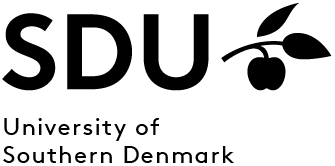
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

## Harris corner detection

In [1]:
try:
    import oip
except Exception:
    oip = None

from oip import show_image, show_images

## Predict in pairs (1 min)

Imagine shifting the small window horizontally, vertically and diagonally.

**Rank a flat region, an edge and a corner by how many shift directions produce
a large intensity change.**

Compare your ranking with a partner, then run the next cell to inspect the
window-change example.

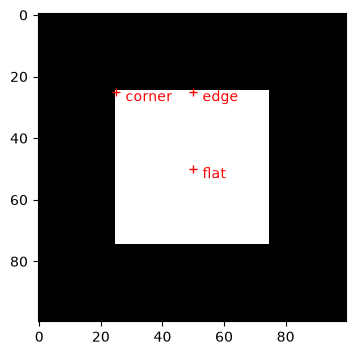

flat: horizontal SSD=0.0, vertical SSD=0.0
edge: horizontal SSD=0.0, vertical SSD=11.0
corner: horizontal SSD=6.0, vertical SSD=6.0


In [3]:
image = oip.week05.square_image()
changes = oip.week05.window_changes(image)

The corner changes for both horizontal and vertical shifts. Along the horizontal edge, horizontal motion gives zero SSD and vertical motion gives positive SSD. Both shifts give zero in the flat interior. This two-shift experiment illustrates the slide intuition; Harris considers all small directions through the structure tensor.

The Corner response function is `det(M) - k * trace(M)**2`. `sigma` controls the Gaussian weighting of derivative products. Positive local maxima are corner candidates.

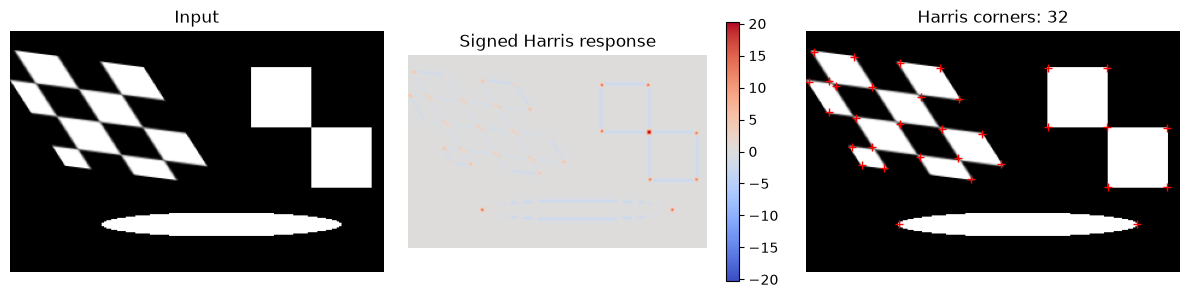

In [4]:
from skimage.feature import corner_harris, corner_peaks

image = oip.week05.harris_image()
sigma = 1.5
threshold = 0.05

response = corner_harris(image, sigma=sigma, k=0.04)

corners = corner_peaks(
    response,
    threshold_rel=threshold,
    threshold_abs=0,
    min_distance=5,
    exclude_border=False,
)
oip.week05.show_corners(image, response, corners)


### Interactive demo — explore Harris parameters

Use the sliders after making a prediction. Change **one parameter at a time**:
integration scale `sigma`, response threshold, or the minimum separation
between retained peaks.

In [5]:
import matplotlib.pyplot as plt
from ipywidgets import FloatSlider, IntSlider, interact

def harris_demo(sigma=1.5, threshold=0.05, min_distance=5):
    demo_response = corner_harris(image, sigma=sigma, k=0.04)
    demo_corners = corner_peaks(
        demo_response,
        threshold_rel=threshold,
        threshold_abs=0,
        min_distance=min_distance,
        exclude_border=False,
    )

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(image, cmap="gray")
    axes[0].plot(
        demo_corners[:, 1],
        demo_corners[:, 0],
        "r+",
        markersize=10,
    )
    axes[0].set_title(f"Detected corners: {len(demo_corners)}")
    axes[1].imshow(demo_response, cmap="magma")
    axes[1].set_title("Harris response")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

interact(
    harris_demo,
    sigma=FloatSlider(
        value=1.5, min=0.5, max=4.0, step=0.5,
        description="sigma",
    ),
    threshold=FloatSlider(
        value=0.05, min=0.01, max=0.40, step=0.01,
        description="threshold",
    ),
    min_distance=IntSlider(
        value=5, min=1, max=20, step=1,
        description="distance",
    ),
);

interactive(children=(FloatSlider(value=1.5, description='sigma', max=4.0, min=0.5, step=0.5), FloatSlider(val…

## Activity — Think–Pair–Vote–Test–Share

1. **Think:** Predict how integration scale, threshold and minimum corner
   distance affect the detections.
2. **Pair:** Compare predictions with a partner and agree on one parameter to
   test.
3. **Vote:** Which change is most likely to merge nearby corner responses?
4. **Test:** Change one variable at a time in the cells below.
5. **Share:** Report one result that needs an explanation.

If useful, ask an LLM for an explanation of the unexpected result, but accept
it only after checking the claim against the image and your parameter sweep.

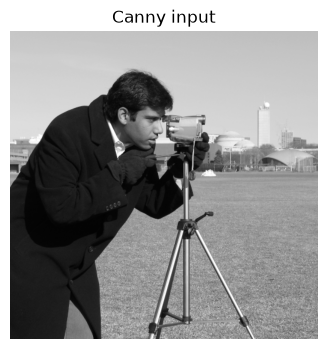

In [7]:
from skimage import data
from skimage.feature import canny
from skimage.util import img_as_float

camera = img_as_float(data.camera())
oip.show_image(camera, "Canny input", vmin=0, vmax=1);

In [33]:
sigma = 1.5
higher_threshold = 0.90
response = corner_harris(camera, sigma=sigma, k=0.04)

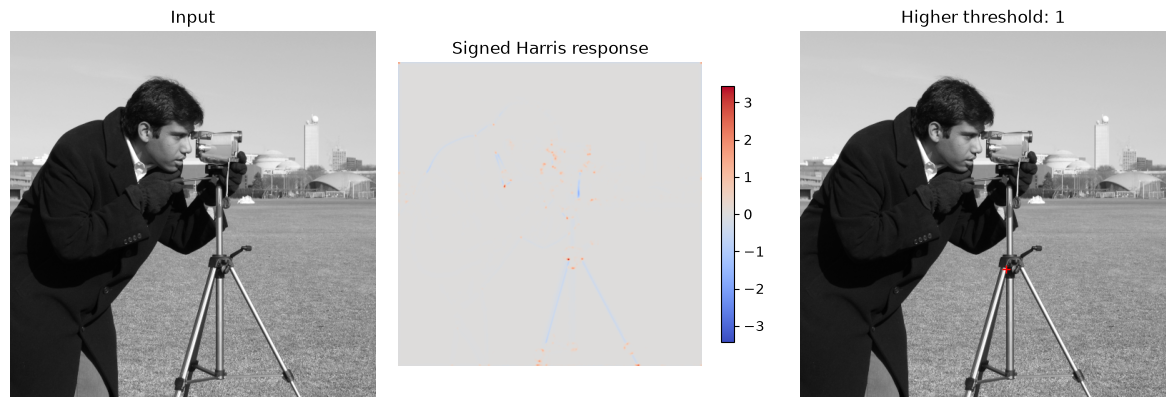

In [34]:
# First change only threshold. Reuse the same response map.
fewer_corners = corner_peaks(response, threshold_rel=higher_threshold, threshold_abs=0,
                             min_distance=5, exclude_border=False)
oip.week05.show_corners(camera, response, fewer_corners, "Higher threshold")

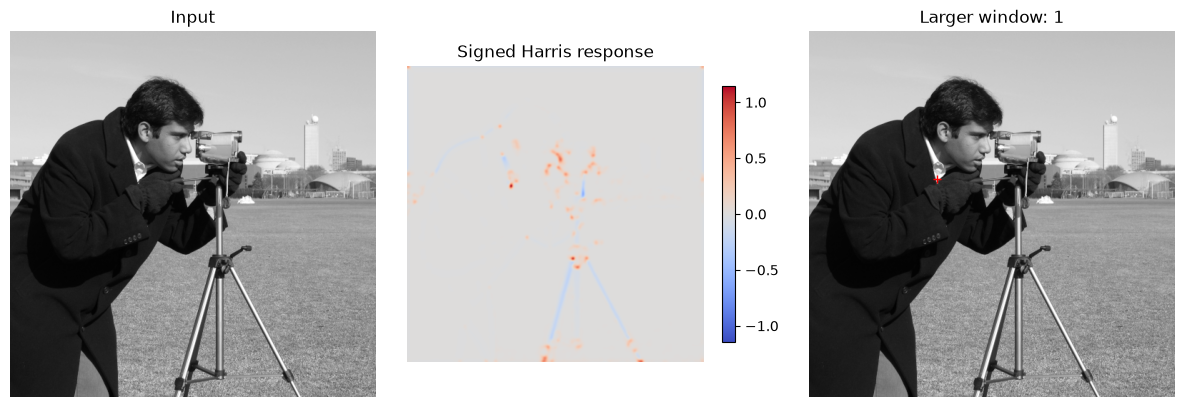

In [35]:
# Now change only the integration scale; restore the original relative threshold.
larger_response = corner_harris(image, sigma=3, k=0.04)
larger_corners = corner_peaks(larger_response, threshold_rel=threshold, threshold_abs=0,
                              min_distance=5, exclude_border=False)
oip.week05.show_corners(image, larger_response, larger_corners, "Larger window")

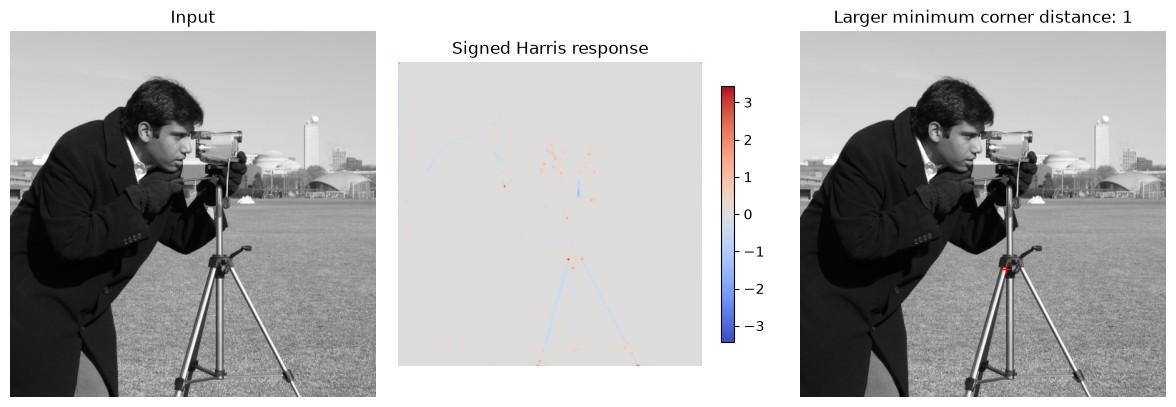

In [36]:
# Finally change only the minimum separation between retained peaks.
farther_corners = corner_peaks(
    response,
    threshold_rel=threshold,
    threshold_abs=0,
    min_distance=12,
    exclude_border=False,
)
oip.week05.show_corners(
    image,
    response,
    farther_corners,
    "Larger minimum corner distance",
)

<details>
For a fixed response, a higher threshold rejects weaker detections. A larger integration window mixes nearby structures and can merge or shift responses; it does not simply guarantee fewer corners. Each relative threshold is scaled to its own response maximum, so the scale comparison does not use a fixed absolute cutoff. Thresholding alone retains patches of pixels; `corner_peaks` applies local maximum selection and minimum separation.
</details>

## Optional programming challenge

Interested in the actual implementation? Continue with
[`l05-6_optional_programming.ipynb`](l05-6_optional_programming.ipynb).
The optional notebook follows the Burger & Burge algorithm structure and keeps
the implementation-focused, scored exercises separate from the lecture demo.

## Assignment — what makes a useful corner?

Work in pairs or groups of three.

1. Choose an image containing meaningful corners; an own image or a
   microscopy/device image is encouraged.
2. Test at least **two integration scales**, **two thresholds**, and one change
   of `min_distance`.
3. Mark three useful detections and up to three questionable detections.
4. Explain the questionable detections using local structure, scale, contrast
   or non-maximum suppression.
5. Compare with another implementation, for example FIJI or another Python
   corner detector.
6. Ask an LLM to explain one disagreement. Check the explanation against the
   image and your parameter sweep.

**Submit:** an annotated result and a short parameter/observation table.

### Share something interesting on Itslearning

This week, **sharing examples and results is encouraged**. You do not need to
submit a polished full solution. If you find an interesting corner-detection
example, post it to the Week 05 Itslearning submission for the class.

Examples worth sharing:

- an own image with unexpectedly good or bad Harris detections;
- a corner that disappears when the integration scale or threshold changes;
- an example where `min_distance` merges or removes nearby candidates;
- a strong response that you would *not* consider a useful corner;
- a disagreement between your implementation, `scikit-image`, or FIJI;
- an LLM explanation that you could confirm — or disprove — experimentally.

A useful post can be **one annotated image + the relevant parameters + 2–4
sentences explaining what the example teaches us**. Pair/group submissions are
very welcome.
